<!-- d2l:prose id=attention-at-scale-md-1 fw=all -->

# The Cost of Attention

Long-context language models process tens or hundreds of thousands of tokens
in a single pass. Because dense self-attention evaluates a score for every
pair of positions, both its arithmetic and its naive memory footprint grow
quadratically with sequence length $n$. At $n = 8{,}192$, a single head
evaluates $6.7 \times 10^7$ query--key pairs (256 MiB in float32).

For several years, $O(n^2)$ memory was widely assumed to be an unavoidable
cost of exact attention. Then @Rabe.Staats.2021 demonstrated—building
on the *online softmax* algorithm of @Milakov.Gimelshein.2018—that
exact attention never requires materializing the $n \times n$ score matrix,
and *FlashAttention* [@Dao.Fu.Ermon.ea.2022] turned tiled online softmax
into an IO-aware GPU kernel that is both faster than naive attention and
linear in memory.

This section counts the FLOPs and memory of dense attention, benchmarks them
on a GPU, derives blockwise online softmax, and compares a chunked
implementation and fused FlashAttention kernels against naive matrix
materialization.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
from torch.nn.attention import SDPBackend, sdpa_kernel

<!-- d2l:prose id=attention-at-scale-md-2 fw=all -->

## Quadratic Time and Memory

### Counting FLOPs

For a multi-head self-attention layer of width $d$ with $H$ heads of width
$d_h = d/H$ over $n$ tokens, the multi-head complexity count
(that section) together with the
row-wise softmax gives

$$
\underbrace{8 n d^2}_{\textrm{projections}} \;+\;
\underbrace{4 n^2 d}_{\textrm{scores and mixing}} \;+\; O(Hn^2)
\quad \textrm{FLOPs}.
$$

The quadratic $4n^2 d$ term ($2n^2 d_h$ for $\mathbf{Q}\mathbf{K}^\top$ and
$2n^2 d_h$ for $\mathbf{A}\mathbf{V}$ across $H$ heads) overtakes the linear
$8nd^2$ projection term once $n > 2d$. For GPT-2 small ($d = 768$, $n =
1{,}024$), projections still dominate; for a model with $d = 4{,}096$ at
$n = 131{,}072$, $n / (2d) = 16$, so scoring and mixing require $16\times$ as
many FLOPs as the attention projections (and roughly $5\times$ as many as the
entire transformer block once the feed-forward network of
that section is included, which moves the block crossover to
$n \approx 6d$).

### Counting Memory

At long contexts, memory often becomes the bottleneck before arithmetic. A
naive implementation materializes both the $n \times n$ score matrix and its
$n \times n$ softmax weight matrix, consuming $8n^2$ bytes per head and
sequence in float32 (versus $O(nd)$ for projections). For one head of width
$d_h = 64$ at $n = 8{,}192$, $\mathbf{Q}, \mathbf{K}, \mathbf{V}$ occupy just
6 MiB together while the two $n \times n$ buffers consume 512 MiB; at $n =
131{,}072$, a single float32 attention matrix would require 64 GiB. During
training, saving attention weights across all 12 layers and 12 heads of GPT-2
small at $n = 8{,}192$ would require $144 \times 256\textrm{ MiB} = 36\textrm{
GiB}$ per sequence.

We verify the $8n^2$-byte scratch footprint on one float32 head ($d_h = 64$)
using `d2l.peak_memory` (that section):

In [3]:
def attention(Q, K, V):
    """softmax(Q K^T / sqrt(d_h)) V through the full score matrix."""
    scores = Q @ K.transpose(-2, -1) / math.sqrt(Q.shape[-1])
    return torch.softmax(scores, dim=-1) @ V

<!-- d2l:prose id=attention-at-scale-md-3 fw=all -->

Evaluating `d2l.peak_memory(attention, Q, Q, Q)` across sequence lengths $n \in \{2048, 4096, 8192, 16384\}$ confirms that each doubling of $n$ quadruples the temporary memory allocation right in line with $8n^2$ bytes:

In [4]:
d_h = 64
for n in [2048, 4096, 8192, 16384]:
    Q = torch.randn(n, d_h, device=d2l.try_gpu())
    mem = d2l.peak_memory(attention, Q, Q, Q)  # Allocator high-water mark
    print(f'n = {n:5d}: measured {mem/2**20:7.1f}'
          f' MiB, predicted 8n^2 B = {8*n*n/2**20:7.1f} MiB')

n =  2048: measured    40.6 MiB, predicted 8n^2 B =    32.0 MiB
n =  4096: measured   129.0 MiB, predicted 8n^2 B =   128.0 MiB
n =  8192: measured   514.0 MiB, predicted 8n^2 B =   512.0 MiB
n = 16384: measured  2052.0 MiB, predicted 8n^2 B =  2048.0 MiB


<!-- d2l:prose id=attention-at-scale-md-4 fw=all -->

### Measuring Time

Timing the same forward pass with `d2l.Benchmark` (that section)
confirms the quadratic runtime growth once $n$ is large enough to amortize
kernel launch latency ($n \ge 8{,}192$):

In [5]:
for n in [2048, 4096, 8192, 16384]:
    Q = torch.randn(n, d_h, device=d2l.try_gpu())
    print(d2l.Benchmark(lambda: attention(Q, Q, Q), desc=f'n = {n:5d}'))

n =  2048: 0.07 ms/call
n =  4096: 0.46 ms/call
n =  8192: 1.84 ms/call


n = 16384: 7.37 ms/call


<!-- d2l:prose id=attention-at-scale-md-5 fw=all -->

## Exact Attention Without the Matrix

### Blockwise Online Softmax

At first glance, the softmax denominator $\sum_{j'} \exp(a_{j'})$ and the
numerical-stability row maximum $\max_{j'} a_{j'}$
(that section) appear to require all $n$
scores before any value can be weighted. *Online softmax*
[@Milakov.Gimelshein.2018] avoids this two-pass requirement by
processing keys in blocks of size $c$ and maintaining three running statistics
per query: the running maximum score $m$, the running denominator sum $s =
\sum_j e^{a_j - m}$, and the unnormalized output accumulator $\mathbf{o} =
\sum_j e^{a_j - m} \mathbf{v}_j$.

When a new block of scores $\{a_j\}$ and values $\{\mathbf{v}_j\}$ arrives,
updating the running maximum to $m' = \max(m, \max_j a_j)$ requires rescaling
the previously accumulated sum $s$ and output $\mathbf{o}$ by $e^{m - m'}$:

$$
\begin{aligned}
m' &= \max\big(m, \max_j a_j\big), \\
s' &= s\, e^{m - m'} + \sum\nolimits_j e^{a_j - m'}, \\
\mathbf{o}' &= \mathbf{o}\, e^{m - m'} + \sum\nolimits_j e^{a_j - m'}\, \mathbf{v}_j.
\end{aligned}
$$

For example, if block 1 has scores $(1, 3)$, then $m = 3$ and $s = e^{-2} +
e^0 \approx 1.135$. If block 2 has scores $(5, 2)$, the new maximum is $m' =
5$, so the block-1 sum is rescaled by $e^{3 - 5} = e^{-2}$ and incremented by
$e^{5 - 5} + e^{2 - 5}$, yielding $s' = e^{-4} + e^{-2} + e^0 + e^{-3}
\approx 1.203$—identical to the standard softmax denominator computed with
the global maximum $5$ known in advance. After the final block,
$\mathbf{o} / s$ equals $\mathrm{softmax}(\mathbf{a})\mathbf{V}$ up to
floating-point round-off, while holding only one $n \times c$ score stripe in
memory at a time (the figure, [@Rabe.Staats.2021]).

![Online softmax processes the score matrix one key block at a time. Of the scores, only the current $n \times c$ stripe is in memory, next to the running maxima, sums and outputs $\mathbf{m}, \mathbf{s}, \mathbf{O}$ of all queries; the full $n \times n$ matrix is never stored.](../img/mdl-attention-online-softmax.svg)

### A Chunked Implementation

We compare full-matrix `causal_attention` against `chunked_attention`, which
steps through key--value blocks of width `chunk_size=512` using
the equation (initializing $m$ and masking future positions with
`finfo(dtype).min` to avoid $-\infty - (-\infty) = \mathrm{NaN}$ when an
entire block is causally masked; see Exercise
2d).

In [6]:
def causal_attention(Q, K, V):
    """Reference: causal attention with the full score matrix."""
    scores = Q @ K.transpose(-2, -1) / math.sqrt(Q.shape[-1])
    mask = d2l.causal_mask(Q.shape[-2], device=Q.device)
    scores.masked_fill_(~mask, torch.finfo(Q.dtype).min)
    return torch.softmax(scores, dim=-1) @ V

def chunked_attention(Q, K, V, chunk_size=512):
    """Exact causal attention, one n-by-chunk_size block at a time."""
    n, d_h = Q.shape
    m = torch.full((n, 1), torch.finfo(Q.dtype).min, device=Q.device)
    s = torch.zeros(n, 1, device=Q.device)
    O = torch.zeros(n, V.shape[-1], device=Q.device)
    pos_q = torch.arange(n, device=Q.device)[:, None]
    for start in range(0, n, chunk_size):
        Kc, Vc = K[start:start + chunk_size], V[start:start + chunk_size]
        pos_k = torch.arange(start, start + Kc.shape[0], device=Q.device)
        scores = Q @ Kc.T / math.sqrt(d_h)
        scores.masked_fill_(pos_k[None, :] > pos_q, torch.finfo(Q.dtype).min)
        m_new = torch.maximum(m, scores.max(dim=-1, keepdim=True).values)
        scale = torch.exp(m - m_new)                  # Rescale the past
        P = torch.exp(scores - m_new)
        s = s * scale + P.sum(dim=-1, keepdim=True)
        O = O * scale + P @ Vc
        m = m_new
    return O / s

<!-- d2l:prose id=attention-at-scale-md-6 fw=all -->

`chunked_attention` matches `causal_attention` to float32 precision ($\sim
10^{-6}$) while reducing peak memory from $O(n^2)$ to $O(nc)$:

In [7]:
n, d_h = 2048, 64
Q, K, V = (torch.randn(n, d_h, device=d2l.try_gpu()) for _ in range(3))
err = (chunked_attention(Q, K, V) - causal_attention(Q, K, V)).abs().max()
print(f'maximum deviation: {float(err):.2e}')

maximum deviation: 2.38e-07


<!-- d2l:prose id=attention-at-scale-md-7 fw=all -->

Comparing `d2l.peak_memory` across $n \in \{2048, 4096, 8192, 16384\}$ verifies that `chunked_attention` replaces the quadratic $O(n^2)$ memory curve of `causal_attention` with linear $O(nc)$ scaling:

n = 16,384: full matrix 2308.0 MiB, chunked  132.4 MiB


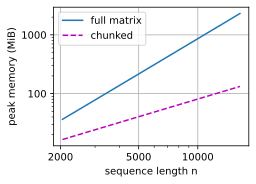

In [8]:
lengths, mems = [2048, 4096, 8192, 16384], [[], []]
for n in lengths:
    Q = torch.randn(n, d_h, device=d2l.try_gpu())
    mems[0].append(d2l.peak_memory(causal_attention, Q, Q, Q) / 2**20)
    mems[1].append(d2l.peak_memory(chunked_attention, Q, Q, Q) / 2**20)
print(f'n = {n:,}: full matrix {mems[0][-1]:6.1f} MiB, '
      f'chunked {mems[1][-1]:6.1f} MiB')
d2l.plot(lengths, mems, 'sequence length n', 'peak memory (MiB)',
         legend=['full matrix', 'chunked'], xscale='log', yscale='log')

<!-- d2l:prose id=attention-at-scale-md-8 fw=all -->

### Memory Traffic and Fused Kernels

A GPU's compute units execute matrix arithmetic orders of magnitude faster
than its off-chip device memory can transfer data (e.g., on an RTX 4090,
$\sim 165$ TFLOP/s in float16 versus $\sim 1$ TB/s of memory bandwidth; see
that section). Data-center cards build this memory from
high-bandwidth memory (HBM) and the RTX 4090 from GDDR6X. We follow the
FlashAttention paper and write HBM for the device memory of either kind.
Naive attention is *memory-bandwidth bound*:
it writes the $n \times n$ score matrix to HBM, reads it back for softmax,
writes the $n \times n$ weights to HBM, and reads them again to multiply by
$\mathbf{V}$—moving $4n^2$ floats across HBM with low arithmetic intensity
(Exercises 4 and
5). Because a Python loop like
`chunked_attention` still launches separate GPU kernels that read and write
every $n \times c$ stripe to HBM, it reduces peak memory allocation without
reducing total HBM traffic.

*FlashAttention* [@Dao.Fu.Ermon.ea.2022] tiles both queries and keys so
that each score block and its running statistics $(m, s, \mathbf{o})$ reside
entirely in fast on-chip SRAM throughout the loop, never touching HBM. For
the backward pass, instead of saving $n \times n$ attention weights, the
forward pass stores only the scalar log-normalizer $\ell = m + \log s$ per
query ($O(n)$ memory) and recomputes the score tiles on chip during
backpropagation.

We benchmark the framework-provided fused FlashAttention kernel
against `causal_attention` on $B = 2$
sequences, $H = 8$ heads, $d_h = 64$, and $n = 8{,}192$ in float16. Including
an unmasked fused run separates the $O(n^2)$ HBM-traffic speedup from the
$\sim 1.5\times$ speedup of skipping upper-triangular causal tiles:

<!-- d2l:prose id=attention-at-scale-md-9 fw=pytorch -->

The fused kernel is `F.scaled_dot_product_attention`.

In [9]:
def fused_attention(Q, K, V, is_causal=True):
    """Attention in PyTorch's fused FlashAttention kernel."""
    with sdpa_kernel(SDPBackend.FLASH_ATTENTION):
        return F.scaled_dot_product_attention(Q, K, V, is_causal=is_causal)

B, H, n = 2, 8, 8192
X = torch.randn(B, H, n, d_h, device=d2l.try_gpu(), dtype=torch.float16)
# The unmasked kernel computes every tile: it shows what skipping saves
for name, f in [('naive', causal_attention), ('fused', fused_attention),
                ('fused, no mask',
                 lambda Q, K, V: fused_attention(Q, K, V, is_causal=False))]:
    t = d2l.Benchmark(lambda: f(X, X, X)).time
    mem = d2l.peak_memory(f, X, X, X)
    print(f'{name:>14}: {t*1e3:6.2f} ms, peak memory {mem/2**20:7.1f} MiB')

         naive:  19.95 ms, peak memory  4176.0 MiB
         fused:   1.08 ms, peak memory    16.5 MiB
fused, no mask:   1.72 ms, peak memory    16.5 MiB


<!-- d2l:prose id=attention-at-scale-md-10 fw=all -->

The fused kernel reduces temporary memory from $\sim 4$ GiB ($16 \cdot 4n^2$
bytes) to a small multiple of the 16 MiB output and runs several times faster
close to the GPU's peak matrix throughput. Even with fused kernels, however,
exact attention still performs $\Theta(n^2 d)$ arithmetic operations;
achieving linear time complexity requires changing the attention mechanism
itself (that section).

## Summary

Dense self-attention requires $8nd^2 + 4n^2d$ FLOPs per layer, so its quadratic score-and-mix work overtakes the linear projections once $n > 2d$. Worse still, materializing the $n \times n$ score and weight matrices allocates $8n^2$ bytes per head in float32 and renders naive attention memory-bandwidth bound on modern GPUs. Online softmax eliminates both $n \times n$ buffers without approximation by processing keys in blocks and maintaining a running maximum $m$, normalizer $s$, and value accumulator $\mathbf{o}$ whose partial sums rescale by $e^{m - m'}$ whenever $m$ increases. FlashAttention fuses this tiled recurrence inside fast on-chip SRAM, reducing off-chip memory to $O(n)$ and achieving multi-fold wall-clock speedups while preserving exact attention and its $\Theta(n^2 d)$ arithmetic count.

## Exercises

1. **Online softmax by hand.** One query meets four keys in two blocks of
   two. Its scores are $(0, 2)$ in the first block and $(1, 3)$ in the
   second, and the values are the numbers $1, 2$ in the first block and
   $3, 4$ in the second.
    1. Apply the equation block by block, starting from
       $m = -\infty$, $s = 0$ and $o = 0$. Record $m$, $s$ and $o$ after
       each block, and divide to obtain the output.
    1. Compute the four softmax weights directly, and check that they give
       the same output.
    1. After the last block, form $\ell = m + \log s$ and recompute each of
       the four weights as $e^{a_j - \ell}$ from its score alone. Check that
       they agree with the weights of the previous part and sum to one, and
       explain why a fused kernel's backward pass can keep $\ell$ instead of
       $m$ and $s$.

1. [code] **The running maximum.** Remove the running maximum from
   `chunked_attention`, so that the state accumulates plain sums of
   $e^{a_j}$. Run the result with $\mathbf{Q}$, $\mathbf{K}$, $\mathbf{V}$
   and the state $s$, $\mathbf{O}$ in float16, on queries scaled up by a
   factor of $10$.
    1. Before running, compute the largest exponent $x$ for which $e^x$ is
       finite in float16, and estimate the fraction of scaled scores that
       exceed it when queries and keys of width $64$ have independent
       standard normal entries.
    1. Run the modified function, and report at which operation the first
       infinite or undefined value appears.
    1. Explain why carrying $m$ bounds every exponent by zero. A term
       $e^{a_j - m'}$ that is smaller than the smallest positive float16
       number rounds to zero. Bound the total contribution of such terms to
       $s$, relative to the term of the largest score, for a row of $n$
       keys.
    1. `chunked_attention` initializes $m$ with the most negative finite
       value of the dtype and masks scores with the same value. Take
       $n = 2c$ for blocks of $c$ keys, and let the loop visit the two key
       blocks in reverse order, so that every score of the first visited
       block is masked for a query in the first block. Trace $m$, $s$, and
       $\mathbf{O}$ for that query through both iterations, and show that
       the final output is still exact.

1. **Merging partial states.** Fix one query with scores $a_j$ and values
   $\mathbf{v}_j$. For a set $B$ of keys, call the triple $(m_B, s_B,
   \mathbf{o}_B)$ that the equation produces from the keys in
   $B$ alone the partial state of $B$, so that $\mathbf{o}_B / s_B$ is the
   attention output restricted to $B$.
    1. Derive the partial state of $B \cup B'$ for disjoint sets $B$ and
       $B'$ from the two partial states, and show that
       the equation is the special case in which $B'$ is a
       single block.
    1. Show that this merge is associative and commutative. Conclude that
       the key blocks can be processed in any order, or in parallel and
       merged in a tree of depth $\lceil \log_2 (n/c) \rceil$ for blocks of
       $c$ keys, and explain why this matters when a single query attends
       to a long cache during generation.
    1. Replace the pair $(m_B, s_B)$ by the single number $\ell_B = m_B +
       \log s_B$ and the triple by $(\ell_B, \bar{\mathbf{o}}_B)$ with
       $\bar{\mathbf{o}}_B = \mathbf{o}_B / s_B$. Express the merged
       $\ell$ and $\bar{\mathbf{o}}$ in these terms, and show that
       $\bar{\mathbf{o}}$ is a convex combination of
       $\bar{\mathbf{o}}_B$ and $\bar{\mathbf{o}}_{B'}$ whose weights
       depend only on $\ell_B$ and $\ell_{B'}$.

1. **Arithmetic intensity of attention.** Consider one head with $n$
   queries and keys of width $d_h$ and values of width $d_v$. Its two matrix
   products, $\mathbf{Q}\mathbf{K}^\top$ and the product of the weights with
   $\mathbf{V}$, cost $2n^2 d_h$ and $2n^2 d_v$ floating-point operations,
   and the softmax costs a few operations per score.
    1. Suppose that the score matrix is written to memory once and read
       once by the softmax, whose output is written once and read once by
       the value product, all in single precision. Count the bytes moved by
       these four passes, and by reading $\mathbf{Q}$, $\mathbf{K}$,
       $\mathbf{V}$ and writing the output.
    1. Neglecting the softmax arithmetic, form the ratio of operations to
       bytes and let $n \to \infty$ at fixed $d_h$ and $d_v$. Show that the
       limit is $(d_h + d_v)/8$, and state how the softmax arithmetic
       changes it.
    1. Redo the limit for inputs and scores in a 16-bit format. Take the
       16-bit throughput and the memory bandwidth of an H100 or a B200 from
       the table, compute the ratio of operations per byte,
       and decide whether attention with $d_h = d_v = 64$ is limited by
       arithmetic or by memory traffic on it.

1. **Traffic of a tiled schedule.** ● By Exercise
   4a,
   the naive layer moves $4n^2$ floats to and from main memory beyond
   the terms linear in $n$, since the score matrix and the weight matrix
   are each written once and read once. Ignore all traffic that is linear
   in $n$.
    1. Suppose that `chunked_attention` runs one operation at a time, each
       reading its inputs from main memory and writing its output back.
       Count, as functions of $n$, $c$, and $d_h$, the floats moved for the
       score stripes, the floats moved for $\mathbf{Q}$ and the accumulator
       $\mathbf{O}$, and the number of operations launched. Which of these
       quantities does chunking reduce relative to the naive layer?
    1. A fused kernel instead holds a tile of $b$ queries, their output
       accumulator, and one tile each of $b$ keys and $b$ values in a fast
       memory of $M$ floats, so that $4bd_h \leq M$; the scores of a tile
       and the running $m$ and $s$ stay in fast memory as well. It loads
       each query tile once, streams
       all key and value tiles past it, and writes each output tile once.
       Show that its traffic beyond the linear terms is $2n^2 d_h / b$
       floats and that the largest admissible tile gives
       $\Theta(n^2 d_h^2 / M)$, the bound that
       @Dao.Fu.Ermon.ea.2022 prove for FlashAttention.
    1. Compute the ratio of the fused traffic to the naive traffic for
       $d_h \in \{64, 128, 256\}$ with $M = 2^{16}$, and state how the head
       width limits the benefit of tiling.

[Discussions](https://d2l.discourse.group/t/36772)